# 10 | CASALS–3DEP elevation comparison

This notebook checks the preserved 0.75 m class-2 reference match for both CASALS granules, verifies the source pulse identities, and recomputes the raw and spatial holdout summaries from the matched records. Ground matching is not repeated.

The outputs separate raw Refh minus 3DEP differences, empirically aligned held-out residuals, and unavailable strict absolute elevation accuracy. The horizontal link uses nominal H5 longitude/latitude in EPSG:4326 transformed to the LAZ horizontal CRS, EPSG:6347. The vertical reference frames remain unresolved.

All new files are written beneath outputs/notebooks/10_3dep_elevation_validation/visual_revision/. Existing revised results are read-only inputs.

In [1]:
from pathlib import Path
import gc, hashlib, json, sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data").is_dir():
    raise FileNotFoundError("Run this notebook from the CASALS project root.")
sys.path.insert(0, str(ROOT))

from research.elevation_comparison import (
    build_class2_reference_grid, build_ground_profile, horizontal_transform_audit,
    independent_ground_interpolation_check, load_matched_elevation_data,
    select_elevation_cases, summarize_matched_elevation_data,
)
from research.validation_figures import (
    elevation_exceedance_table, plot_elevation_case_board, plot_elevation_error_board,
    plot_ground_profile, plot_reference_coverage, plot_spatial_snr_board,
)

H5_DIR = ROOT / "data/raw/casals_l1b"
LAZ_DIR = ROOT / "data/reference/3dep"
ROI_PATH = ROOT / "data/reference/landcover_rois/roi_manifest.geojson"
REVISED_ROOT = ROOT / "outputs/notebooks/10_3dep_elevation_validation/revised"
OUT_ROOT = ROOT / "outputs/notebooks/10_3dep_elevation_validation/visual_revision"
OUT_ROOT.mkdir(parents=True, exist_ok=True)
H5_PATHS = sorted(H5_DIR.glob("casals_l1b_202411*T*_001_02.h5"))
if len(H5_PATHS) != 2:
    raise FileNotFoundError(f"Expected two CASALS H5 granules; found {len(H5_PATHS)}.")
ROI_MANIFEST = json.loads(ROI_PATH.read_text(encoding="utf-8"))
SPLIT_SITES = {
    "casals_l1b_20241112T165718_001_02": ("nov12_east_cropland_01", "nov12_southeast_cropland_02"),
    "casals_l1b_20241118T171757_001_02": ("field_site_01", "field_site_02"),
}
GROSS_ERROR_THRESHOLD_M = 2.0
THRESHOLDS_M = (0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(16 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def json_safe(value):
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, Path):
        return str(value)
    return value

H5_BY_STEM = {path.stem: path for path in H5_PATHS}
LAZ_BY_STEM = {}
for stem in H5_BY_STEM:
    matches = sorted(LAZ_DIR.glob(f"{stem}_*.laz"))
    if len(matches) != 1:
        raise FileNotFoundError(f"Expected one paired LAZ for {stem}; found {len(matches)}.")
    LAZ_BY_STEM[stem] = matches[0]

INPUT_MANIFEST = {"analysis": "CASALS–3DEP visual revision", "inputs": {}}
for stem, h5_path in H5_BY_STEM.items():
    laz_path = LAZ_BY_STEM[stem]
    INPUT_MANIFEST["inputs"][stem] = {
        "h5_path": str(h5_path.relative_to(ROOT)), "h5_size_bytes": h5_path.stat().st_size,
        "h5_sha256": sha256_file(h5_path), "laz_path": str(laz_path.relative_to(ROOT)),
        "laz_size_bytes": laz_path.stat().st_size, "laz_sha256": sha256_file(laz_path),
        "preserved_match_root": str((REVISED_ROOT / stem).relative_to(ROOT)),
    }
(OUT_ROOT / "input_manifest.json").write_text(json.dumps(INPUT_MANIFEST, indent=2), encoding="utf-8")
display(pd.DataFrame([
    {"granule_id": stem, "H5 bytes": item["h5_size_bytes"], "LAZ bytes": item["laz_size_bytes"],
     "H5 SHA256": item["h5_sha256"][:16], "LAZ SHA256": item["laz_sha256"][:16]}
    for stem, item in INPUT_MANIFEST["inputs"].items()
]))

,granule_id,H5 bytes,LAZ bytes,H5 SHA256,LAZ SHA256
0,casals_l1b_20241112T165718_001_02,14039701685,48263708,637ba73ca9966b86,a9c4e079f4f0664f
1,casals_l1b_20241118T171757_001_02,14082437919,595959424,dac3d5ed0116083f,3334b364c9709f48


## 1. Data and reference assumptions

The preserved full-granule plane matches are checked against current H5 pulse IDs, H5 scalar fields, nominal coordinates, LAZ header/sidecar identity, and the raw difference formula. The reference coverage figure uses a deterministic sample for display; counts come from all saved matched H5 records. A held-out subset of real class-2 LAZ points provides a separate interpolation sanity check.

## 2. Ground matching and empirical alignment

The two calibration and test sites are fixed in the ROI manifest before residual inspection. For each SNR population, the median difference in the calibration site is subtracted from the separate test-site differences. The resulting holdout values describe relative site-to-site agreement. They do not transform either dataset into a verified common vertical frame.

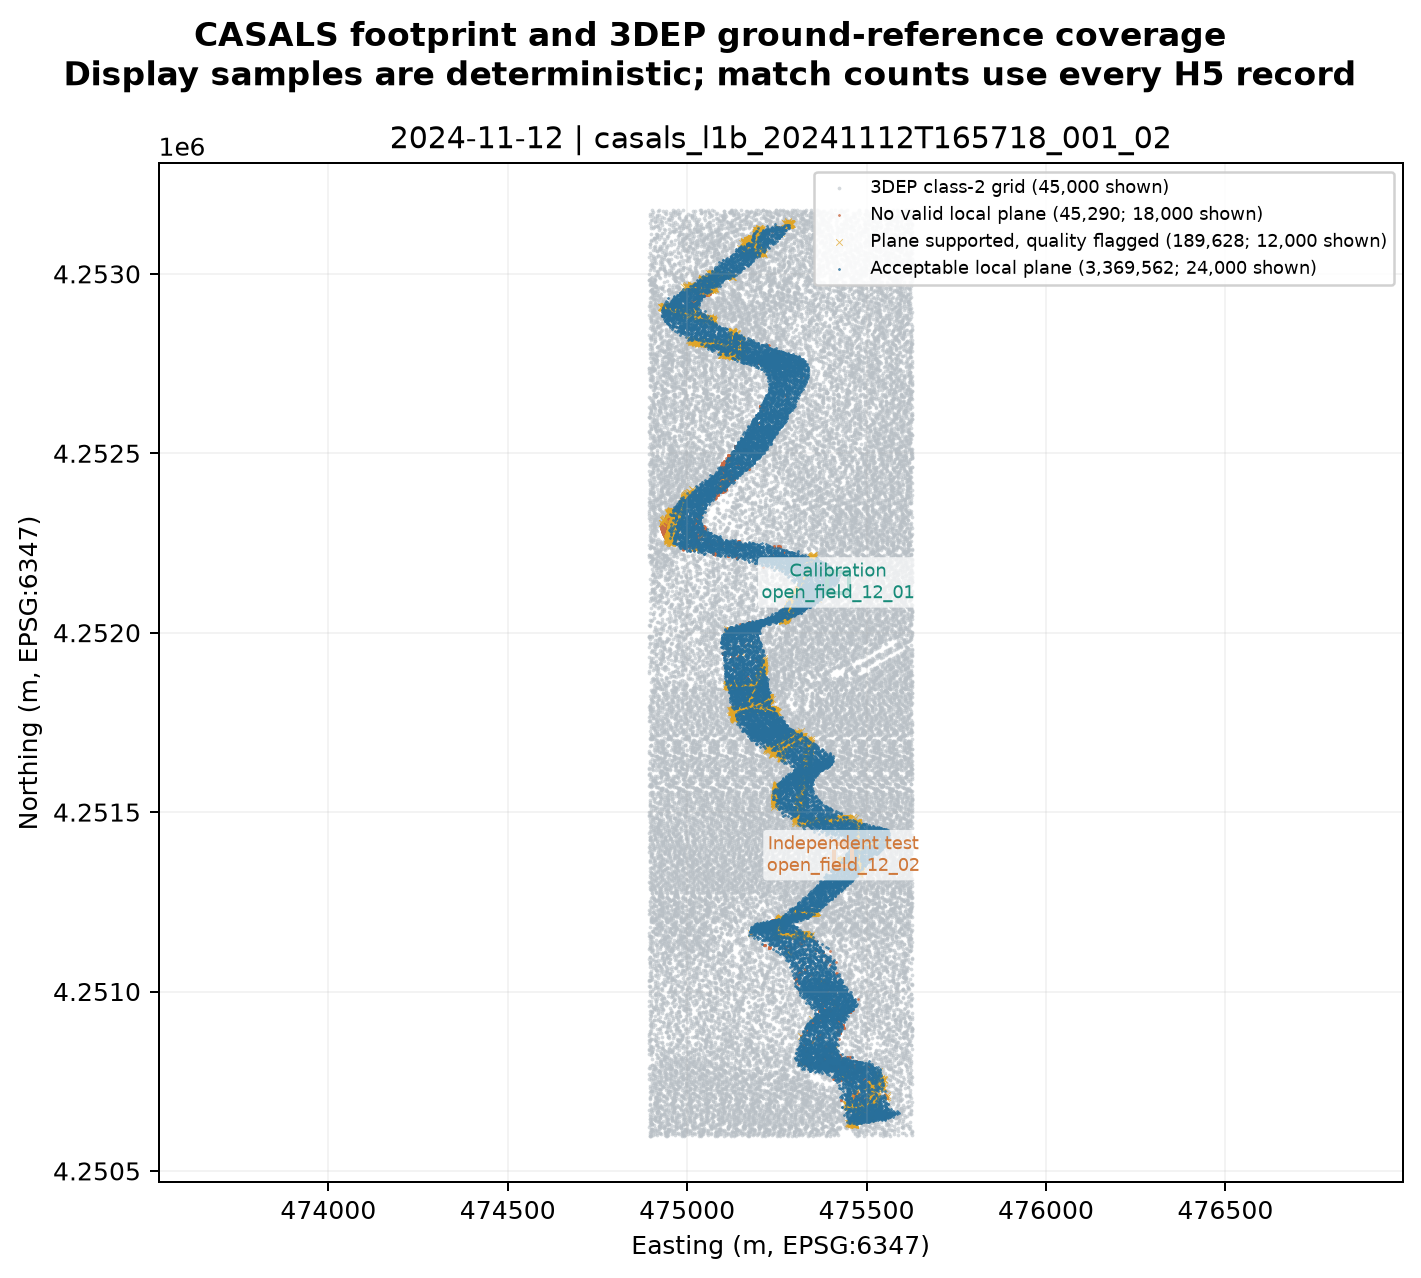

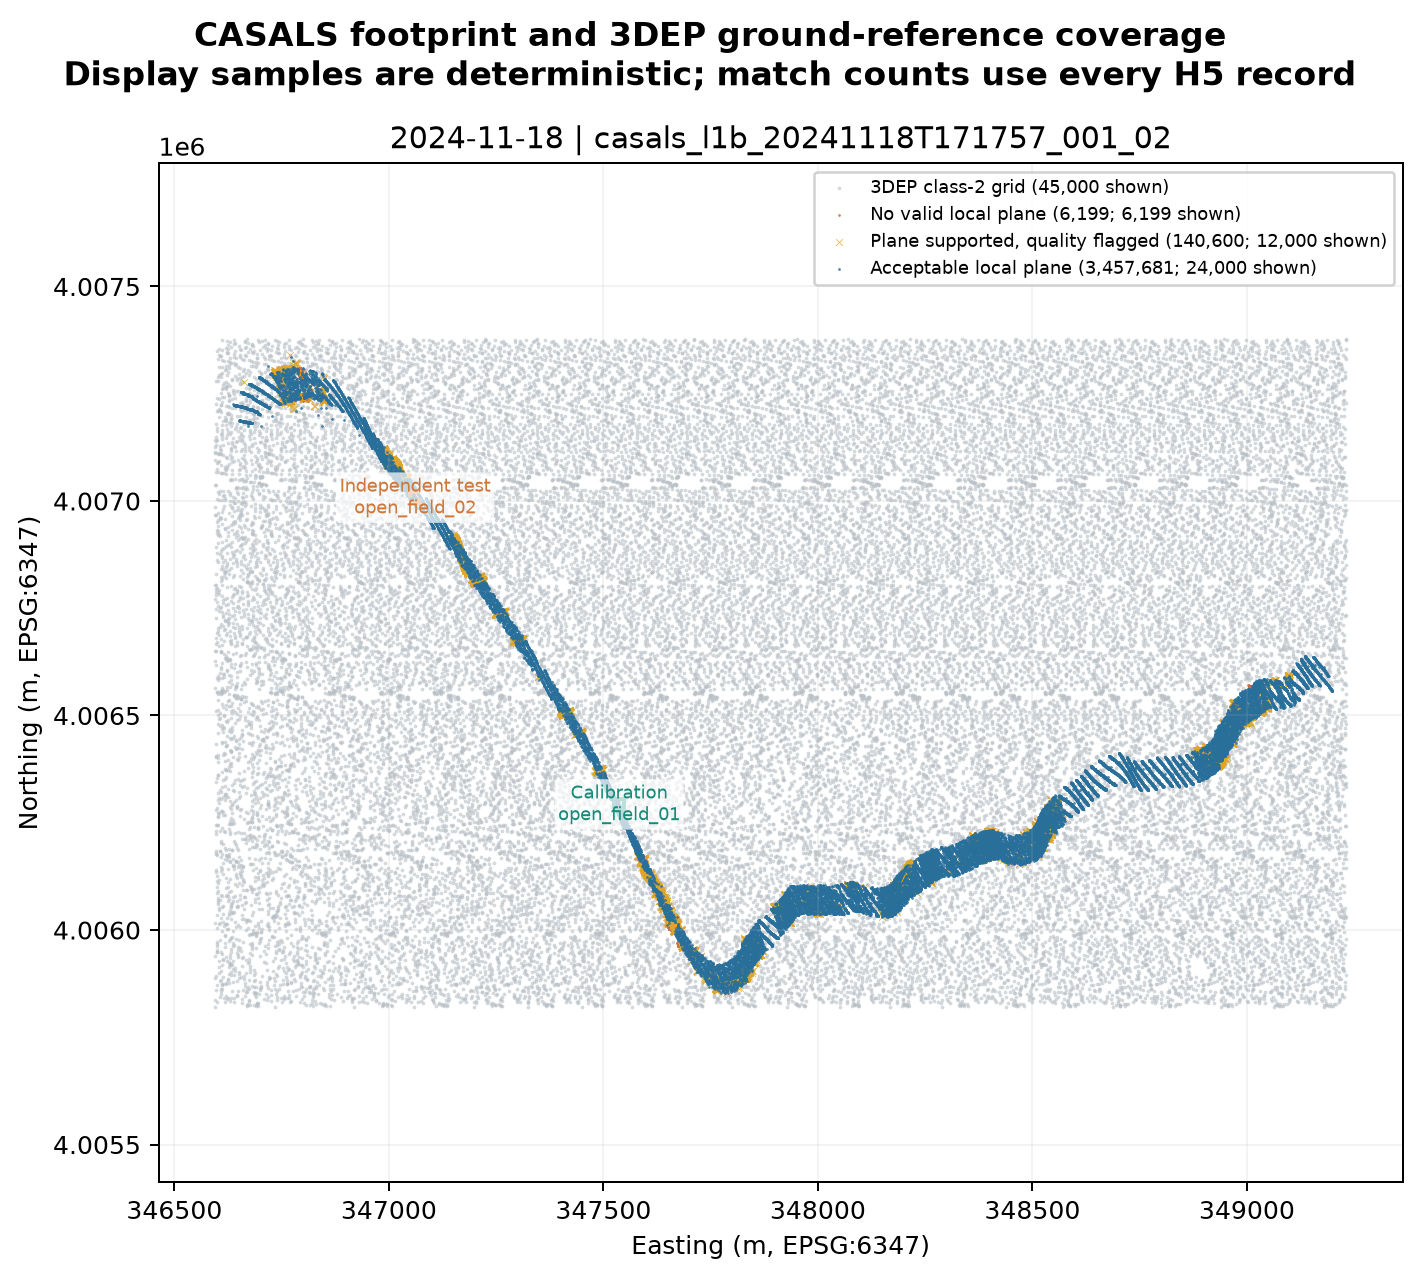

,granule_id,snr_stratum,n_supported_acceptable,median_m,rmse_m_raw,nmad_m_raw,test_n,empirical_vertical_offset_m,rmse_m_holdout,nmad_m_holdout
0,casals_l1b_20241112T165718_001_02,all_valid_refh,3369562,-37.570692,93.741406,43.236901,14885,-37.662703,84.331824,0.295433
1,casals_l1b_20241112T165718_001_02,snr_ge_3,482173,-37.660667,40.505497,0.144846,4274,-37.659448,8.521722,0.117385
2,casals_l1b_20241112T165718_001_02,snr_ge_5,39811,-37.658019,37.665552,0.119806,445,-37.658648,0.132138,0.087637
3,casals_l1b_20241118T171757_001_02,all_valid_refh,3457681,-37.961648,45.272553,0.227456,8924,-37.980111,19.122557,0.094872
4,casals_l1b_20241118T171757_001_02,snr_ge_3,2600908,-37.995586,36.567594,0.137270,8623,-37.981134,0.468919,0.091916
5,casals_l1b_20241118T171757_001_02,snr_ge_5,1703603,-38.017253,37.760945,0.098759,6615,-37.979392,0.096626,0.087440


Held-out class-2 interpolation checks:


,granule_id,validation_n,plane_supported_n,plane_acceptable_n,unsupported_n
0,casals_l1b_20241112T165718_001_02,464,385,361,0
1,casals_l1b_20241118T171757_001_02,6396,6376,6115,0


In [2]:
PLOT_STATE = {}
RAW_TABLES, HOLDOUT_TABLES, SUPPORT_TABLES, INTERPOLATION_SUMMARIES = [], [], [], []
EXCEEDANCE_TABLES, CASE_MANIFEST_ROWS = [], []
reference_grid_rows = []

for stem, h5_path in H5_BY_STEM.items():
    laz_path = LAZ_BY_STEM[stem]
    preserved_dir = REVISED_ROOT / stem
    data = load_matched_elevation_data(h5_path, laz_path, preserved_dir)
    matched = data["matched"]
    analysis = summarize_matched_elevation_data(data)

    ground_xy, ground_z, validation_xyz, grid_meta = build_class2_reference_grid(
        laz_path, resolution_m=0.75, validation_stride=10_000,
    )
    validation_rows, validation_summary = independent_ground_interpolation_check(
        ground_xy, ground_z, validation_xyz,
    )
    validation_rows.to_csv(OUT_ROOT / f"{stem}_held_out_3dep_interpolation.csv", index=False)
    INTERPOLATION_SUMMARIES.append({"granule_id": stem, **validation_summary})
    reference_grid_rows.append({"granule_id": stem, **grid_meta,
                                "independent_interpolation_check": validation_summary})

    matched_ids = matched.pulse_index.to_numpy(dtype=np.int64)
    supported = np.zeros(len(data["refh"]), dtype=bool)
    acceptable = np.zeros(len(data["refh"]), dtype=bool)
    supported[matched_ids] = True
    acceptable[matched_ids] = matched.surface_acceptable.to_numpy(dtype=bool)
    valid_xy = np.isfinite(data["x"]) & np.isfinite(data["y"])
    calibration_site, test_site = SPLIT_SITES[stem]
    roi_views = []
    for feature in ROI_MANIFEST["features"]:
        props = feature["properties"]
        if props.get("granule_id") != stem or props.get("site_id") not in {calibration_site, test_site}:
            continue
        coords = np.asarray(feature["geometry"]["coordinates"][0], dtype=np.float64)
        x, y, _ = horizontal_transform_audit(coords[:, 0], coords[:, 1], target_crs="EPSG:6347")
        role = "Calibration" if props["site_id"] == calibration_site else "Independent test"
        roi_views.append({"roi_id": props["roi_id"], "role": role,
                          "xy": np.column_stack((x, y)), "color": "#178b79" if role == "Calibration" else "#cf783a",
                          "linestyle": "-" if role == "Calibration" else "--"})
    coverage_path = OUT_ROOT / f"10-A_reference_coverage_{stem}.png"
    plot_reference_coverage([{
        "granule_id": stem, "date": "2024-11-12" if "20241112" in stem else "2024-11-18",
        "ground_xy": ground_xy, "x": data["x"], "y": data["y"], "valid": valid_xy,
        "unsupported": valid_xy & ~supported,
        "flagged": valid_xy & supported & ~acceptable,
        "acceptable": valid_xy & acceptable, "rois": roi_views,
    }], coverage_path)
    display(Image(filename=str(coverage_path)))

    raw_metrics = analysis["raw_metrics"].copy()
    holdout_metrics = analysis["holdout_metrics"].copy()
    RAW_TABLES.append(raw_metrics)
    HOLDOUT_TABLES.append(holdout_metrics)
    SUPPORT_TABLES.append(data["support_source"].assign(granule_id=stem))
    exceedance = elevation_exceedance_table(stem, analysis["holdout_values"], THRESHOLDS_M)
    EXCEEDANCE_TABLES.append(exceedance)

    all_valid_holdout = holdout_metrics.loc[holdout_metrics.snr_stratum == "all_valid_refh"].iloc[0]
    snr3_holdout = holdout_metrics.loc[holdout_metrics.snr_stratum == "snr_ge_3"].iloc[0]
    test_rows = matched.loc[
        (matched.spatial_split.astype(str) == "independent_test")
        & matched.surface_acceptable.astype(bool)
        & (matched.refh_snr >= 3.0)
    ].copy().reset_index(drop=True)
    test_residual = test_rows.raw_difference_plane_m.to_numpy(dtype=np.float64) - float(snr3_holdout.empirical_vertical_offset_m)
    gross = np.abs(test_residual) > GROSS_ERROR_THRESHOLD_M
    gross_rows = test_rows.loc[gross].copy()
    gross_rows["empirical_holdout_residual_snr_ge_3_m"] = test_residual[gross]
    gross_rows["gross_error_display_threshold_m"] = GROSS_ERROR_THRESHOLD_M
    gross_rows.to_csv(OUT_ROOT / f"{stem}_all_gross_errors_snr_ge_3.csv", index=False)

    _, selected = select_elevation_cases(
        matched, calibration_offset_m=float(all_valid_holdout.empirical_vertical_offset_m),
        gross_error_threshold_m=GROSS_ERROR_THRESHOLD_M,
    )
    plot_cases = []
    for item in selected:
        record = {"granule_id": stem, "selection_role": item["selection_role"],
                  "selection_status": item["selection_status"], "selection_rule": item["selection_rule"]}
        row = item["row"]
        if row is not None:
            record.update({key: row[key] for key in (
                "pulse_index", "track_num", "sweep_num", "refh_snr", "casals_refh_m",
                "reference_height_local_plane_m", "raw_difference_plane_m", "local_slope_deg",
                "ground_roughness_nmad_m", "neighbor_count_within_3m", "easting_m_epsg6347",
                "northing_m_epsg6347",
            )})
            case_x, case_y = float(row.easting_m_epsg6347), float(row.northing_m_epsg6347)
            local = np.hypot(ground_xy[:, 0] - case_x, ground_xy[:, 1] - case_y) <= 25.0
            support = pd.DataFrame({"easting_m": ground_xy[local, 0], "northing_m": ground_xy[local, 1],
                                    "height_m": ground_z[local]})
            near = np.hypot(matched.easting_m_epsg6347 - case_x,
                            matched.northing_m_epsg6347 - case_y) <= 25.0
            plot_cases.append({"row": row,
                               "residual_m": float(row.raw_difference_plane_m - all_valid_holdout.empirical_vertical_offset_m),
                               "selection_role": item["selection_role"],
                               "ground_points": support,
                               "nearby_casals": matched.loc[near, ["easting_m_epsg6347", "northing_m_epsg6347"]].copy()})
            record["empirical_holdout_residual_m"] = float(row.raw_difference_plane_m - all_valid_holdout.empirical_vertical_offset_m)
        CASE_MANIFEST_ROWS.append(record)

    profile, profile_track = build_ground_profile(
        matched, calibration_offset_m=float(all_valid_holdout.empirical_vertical_offset_m), minimum_pulses=25,
    )
    profile.to_csv(OUT_ROOT / f"{stem}_ground_profile_track_{profile_track}.csv", index=False)
    PLOT_STATE[stem] = {
        "h5_path": h5_path, "analysis": analysis, "raw_metrics": raw_metrics,
        "holdout_metrics": holdout_metrics, "exceedance": exceedance,
        "test_rows": test_rows, "test_residual": test_residual,
        "gross_error_count_snr_ge_3": int(gross.sum()), "cases": plot_cases,
        "profile": profile, "profile_track": profile_track,
        "reference_grid": grid_meta, "interpolation": validation_summary,
        "audit": data["audit"], "horizontal_transform": data["horizontal_transform"],
    }
    del data, matched, ground_xy, ground_z, validation_xyz, validation_rows
    gc.collect()

RAW_METRICS = pd.concat(RAW_TABLES, ignore_index=True)
HOLDOUT_METRICS = pd.concat(HOLDOUT_TABLES, ignore_index=True)
SUPPORT_SUMMARY = pd.concat(SUPPORT_TABLES, ignore_index=True)
EXCEEDANCE = pd.concat(EXCEEDANCE_TABLES, ignore_index=True)
CASE_MANIFEST = pd.DataFrame(CASE_MANIFEST_ROWS)
RAW_METRICS.to_csv(OUT_ROOT / "raw_elevation_metrics.csv", index=False)
HOLDOUT_METRICS.to_csv(OUT_ROOT / "empirical_holdout_metrics.csv", index=False)
SUPPORT_SUMMARY.to_csv(OUT_ROOT / "reference_ground_support.csv", index=False)
EXCEEDANCE.to_csv(OUT_ROOT / "empirical_holdout_exceedance.csv", index=False)
CASE_MANIFEST.to_csv(OUT_ROOT / "representative_case_manifest.csv", index=False)
(OUT_ROOT / "reference_grid_and_interpolation_summary.json").write_text(
    json.dumps(json_safe(reference_grid_rows), indent=2, allow_nan=False), encoding="utf-8",
)
(OUT_ROOT / "reference_frame_audit.json").write_text(
    json.dumps(json_safe({stem: PLOT_STATE[stem]["audit"] for stem in PLOT_STATE}), indent=2, allow_nan=False),
    encoding="utf-8",
)

summary_table = RAW_METRICS.merge(
    HOLDOUT_METRICS[["granule_id", "snr_stratum", "empirical_vertical_offset_m", "test_n", "rmse_m", "nmad_m"]],
    on=["granule_id", "snr_stratum"], suffixes=("_raw", "_holdout"), validate="one_to_one",
)
display(summary_table[["granule_id", "snr_stratum", "n_supported_acceptable", "median_m", "rmse_m_raw",
                       "nmad_m_raw", "test_n", "empirical_vertical_offset_m", "rmse_m_holdout", "nmad_m_holdout"]])
print("Held-out class-2 interpolation checks:")
display(pd.DataFrame(INTERPOLATION_SUMMARIES)[["granule_id", "validation_n", "plane_supported_n",
                                               "plane_acceptable_n", "unsupported_n"]])

## 3. Elevation error distributions

Each comparison board keeps the full raw and holdout ranges, enlarges the central holdout distribution, and shows the exceedance curve for every SNR stratum. The zoom panel reports how many test samples fall outside its view; none are removed from metrics or the full-range panels.

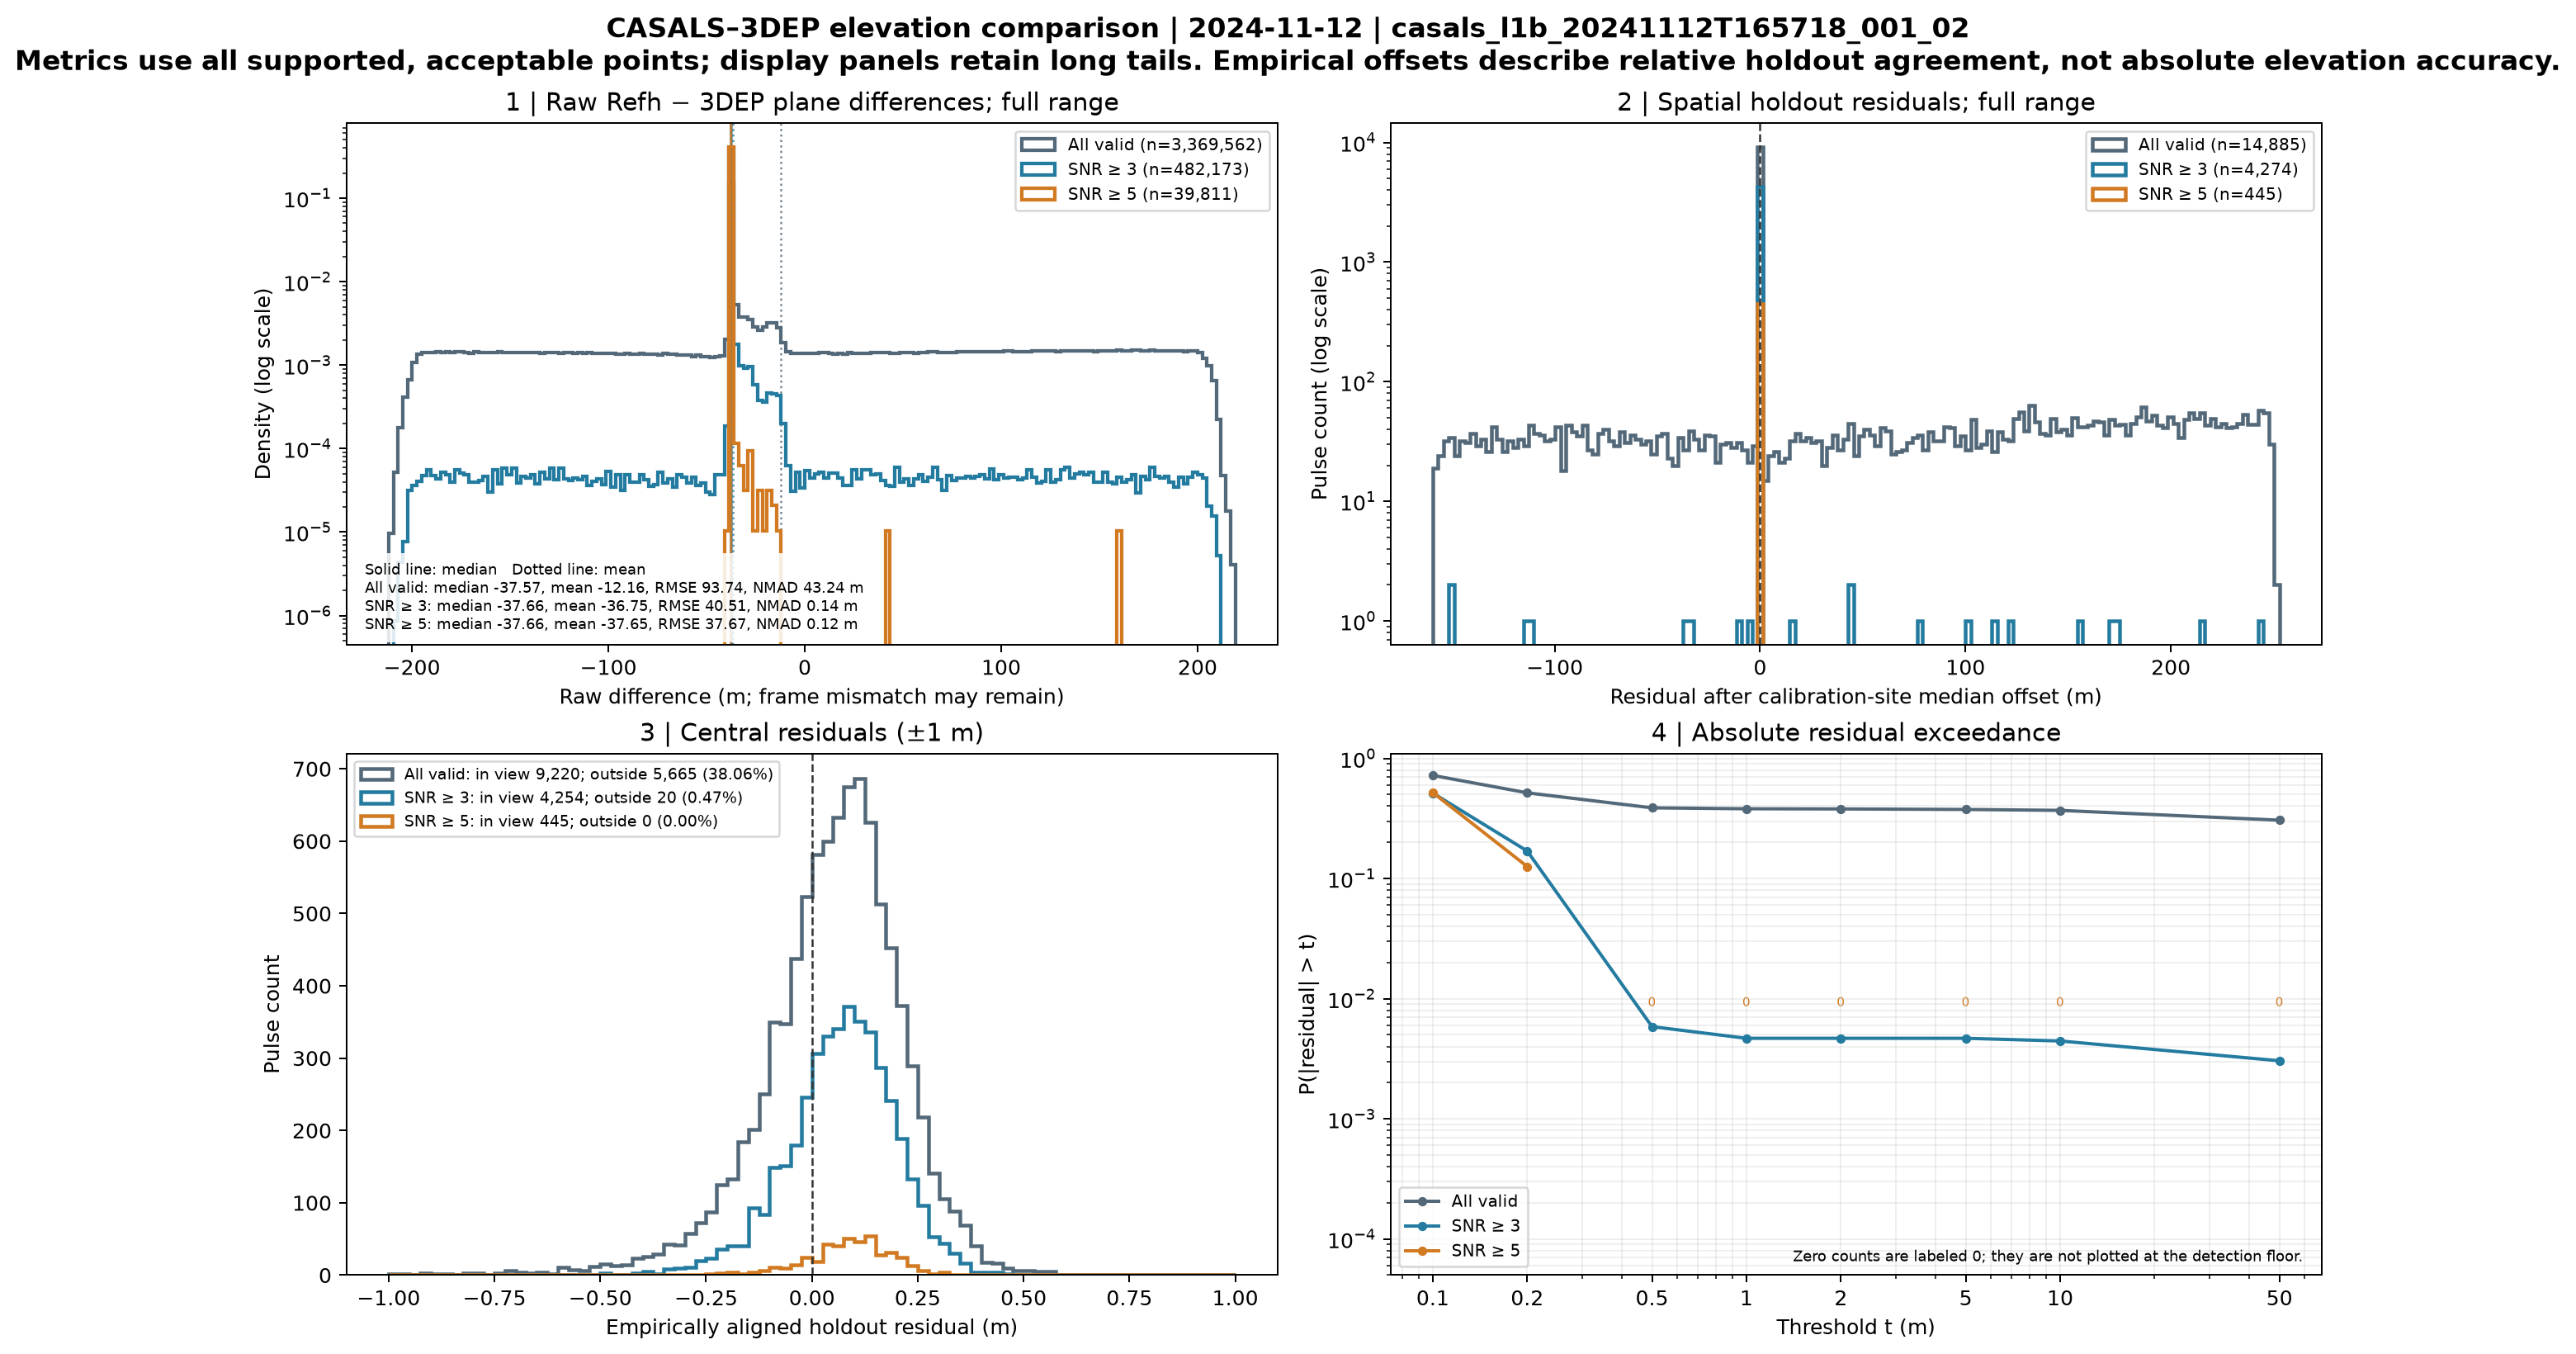

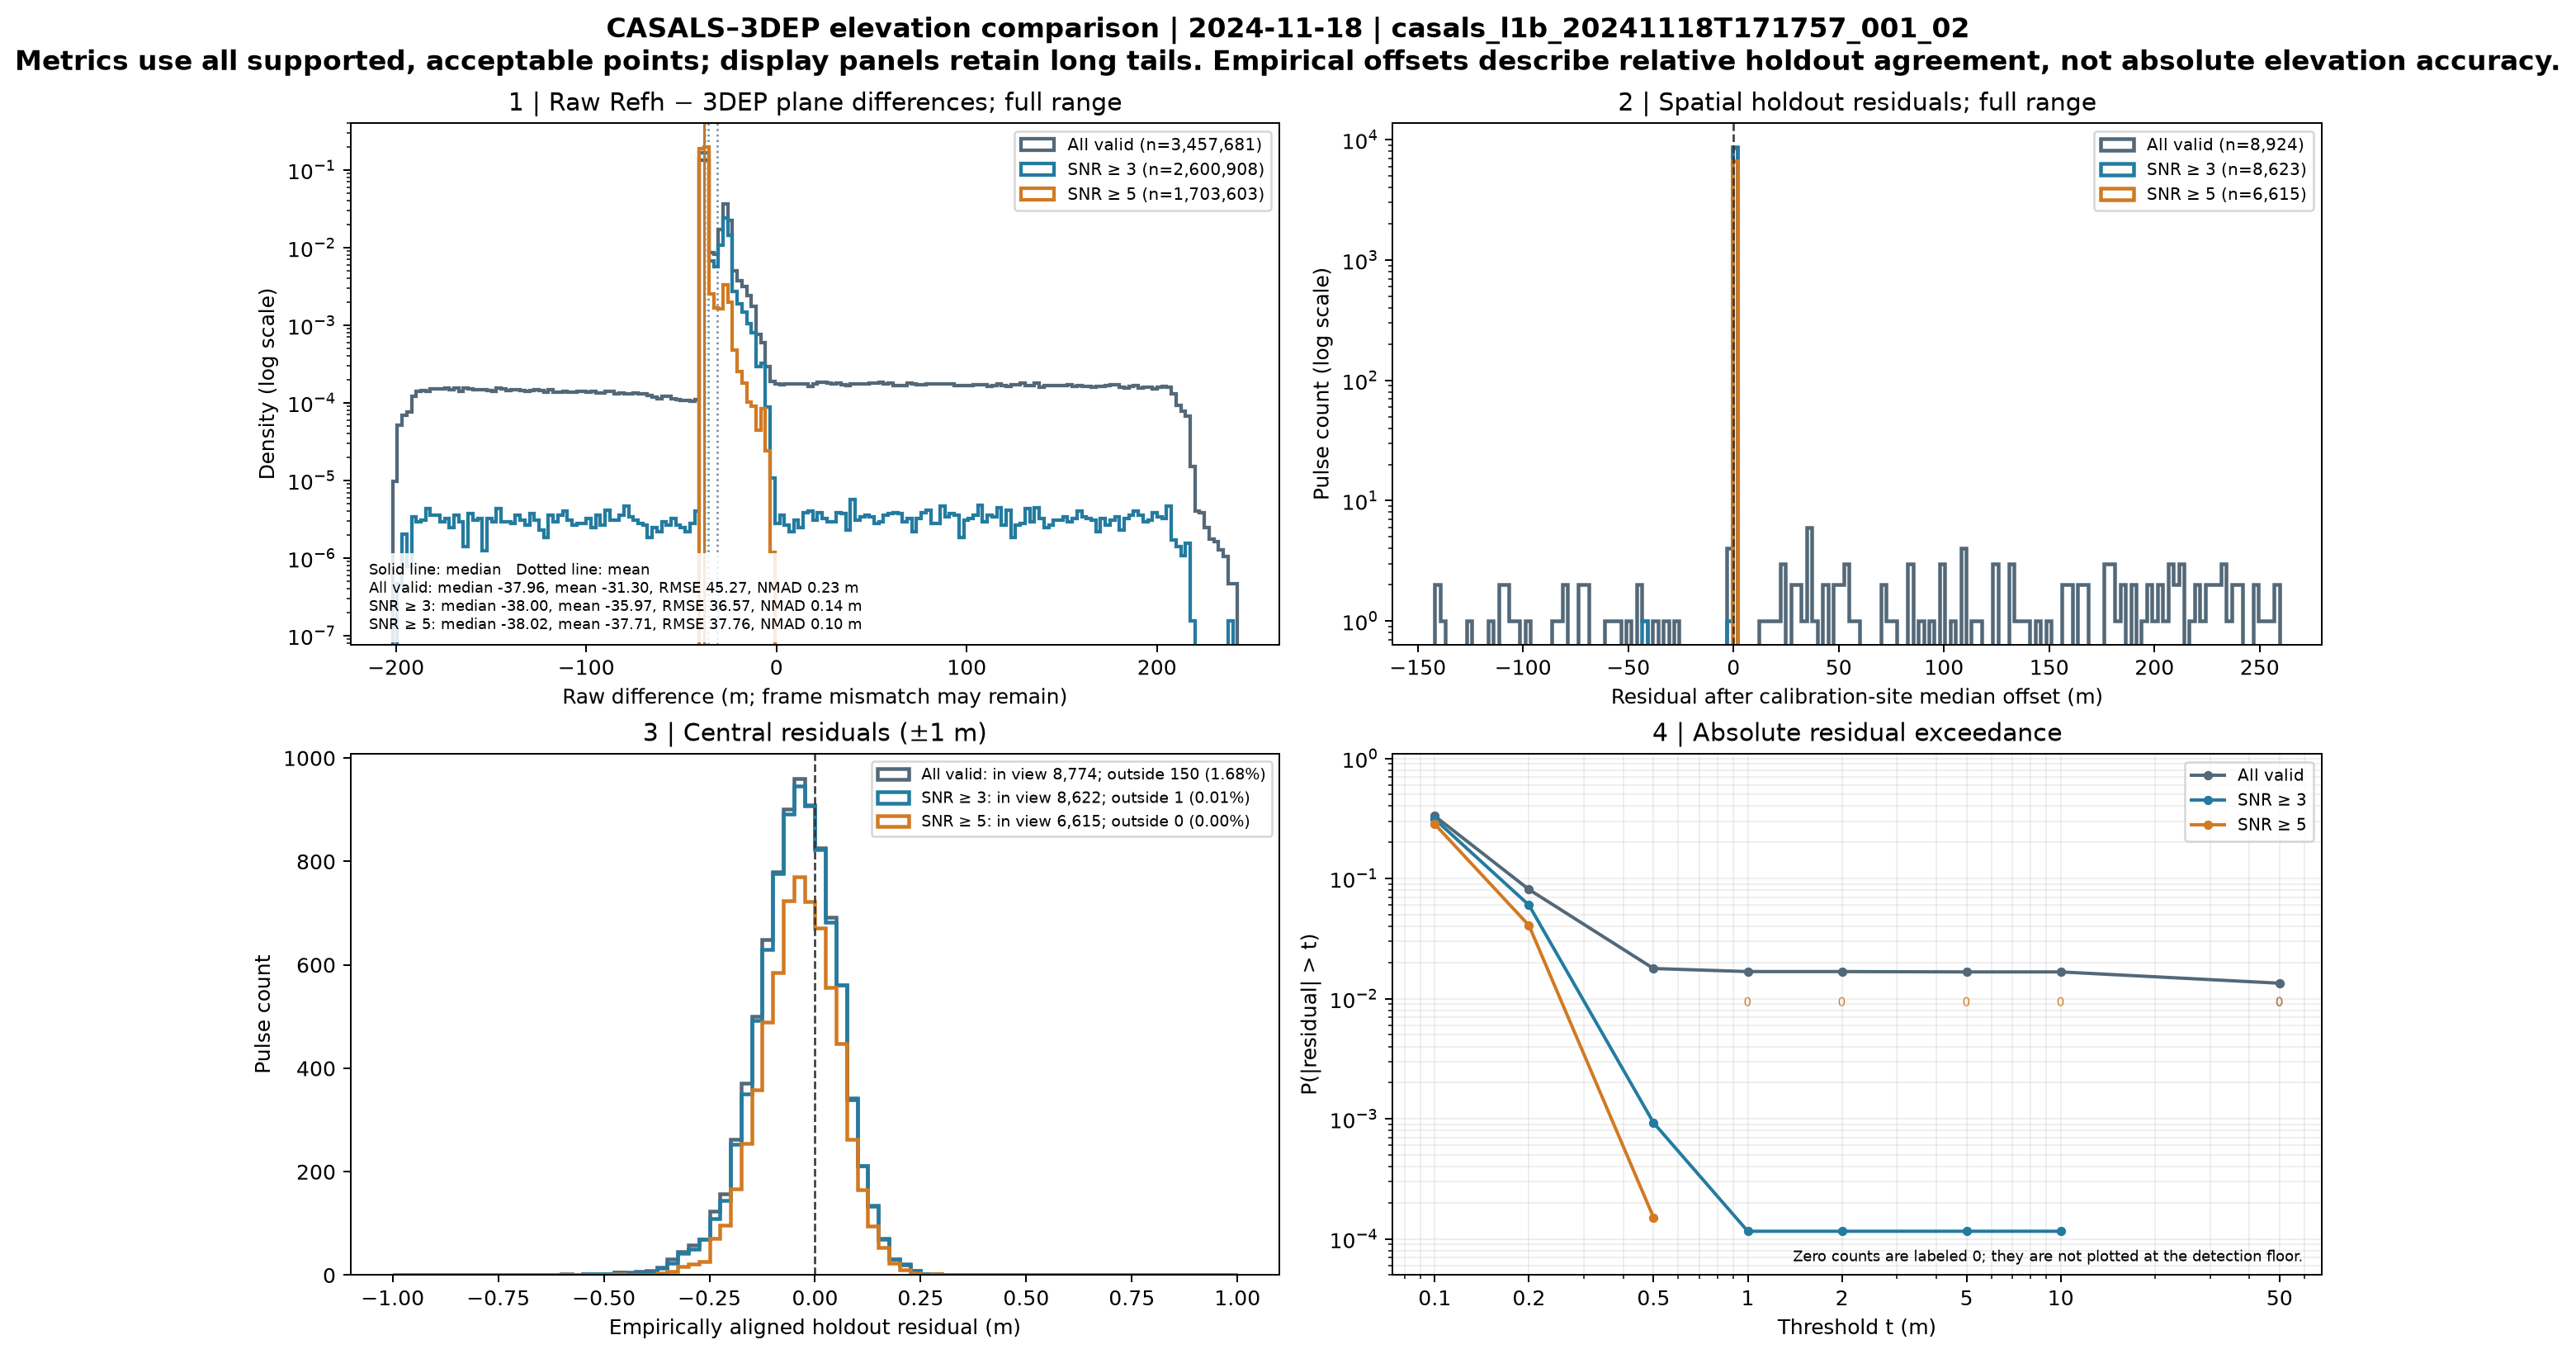

Holdout metrics; empirical offsets are estimated in the separate calibration sites:


,granule_id,snr_stratum,calibration_n,test_n,empirical_vertical_offset_m,rmse_m,nmad_m,absolute_p95_m
0,casals_l1b_20241112T165718_001_02,all_valid_refh,17974,14885,-37.662703,84.331824,0.295433,209.175811
1,casals_l1b_20241112T165718_001_02,snr_ge_3,5203,4274,-37.659448,8.521722,0.117385,0.278294
2,casals_l1b_20241112T165718_001_02,snr_ge_5,302,445,-37.658648,0.132138,0.087637,0.230114
3,casals_l1b_20241118T171757_001_02,all_valid_refh,7140,8924,-37.980111,19.122557,0.094872,0.242678
4,casals_l1b_20241118T171757_001_02,snr_ge_3,7015,8623,-37.981134,0.468919,0.091916,0.212031
5,casals_l1b_20241118T171757_001_02,snr_ge_5,6225,6615,-37.979392,0.096626,0.087440,0.189521


In [3]:
for stem, state in PLOT_STATE.items():
    plot_metrics = {"all_valid_refh": "All valid", "snr_ge_3": "SNR ≥ 3", "snr_ge_5": "SNR ≥ 5"}
    raw_for_plot = {label: state["analysis"]["raw_values"][plot_metrics[key]]
                    for key, label in plot_metrics.items()}
    holdout_for_plot = {label: state["analysis"]["holdout_values"][plot_metrics[key]]
                        for key, label in plot_metrics.items()}
    raw_display_metrics = {plot_metrics[row.snr_stratum]: row._asdict()
                           for row in state["raw_metrics"].itertuples(index=False)}
    holdout_display_metrics = {plot_metrics[row.snr_stratum]: row._asdict()
                               for row in state["holdout_metrics"].itertuples(index=False)}
    date = "2024-11-12" if "20241112" in stem else "2024-11-18"
    path = OUT_ROOT / f"10-B_error_board_{stem}.png"
    plot_elevation_error_board(
        granule_id=stem, date=date, raw_by_stratum=raw_for_plot,
        holdout_by_stratum=holdout_for_plot, raw_metrics=raw_display_metrics,
        holdout_metrics=holdout_display_metrics, exceedance=state["exceedance"],
        output_path=path, zoom_m=1.0,
    )
    display(Image(filename=str(path)))

print("Holdout metrics; empirical offsets are estimated in the separate calibration sites:")
display(HOLDOUT_METRICS[["granule_id", "snr_stratum", "calibration_n", "test_n",
                         "empirical_vertical_offset_m", "rmse_m", "nmad_m", "absolute_p95_m"]])

## 4. Spatial patterns and representative cases

The spatial board maps independent-test observations with SNR ≥ 3. Every observation is retained; the 2 m line only highlights gross residuals for inspection. Waveform cases are chosen by fixed rules from the independent-test population, then paired with their original H5 waveform and nearby class-2 reference support.

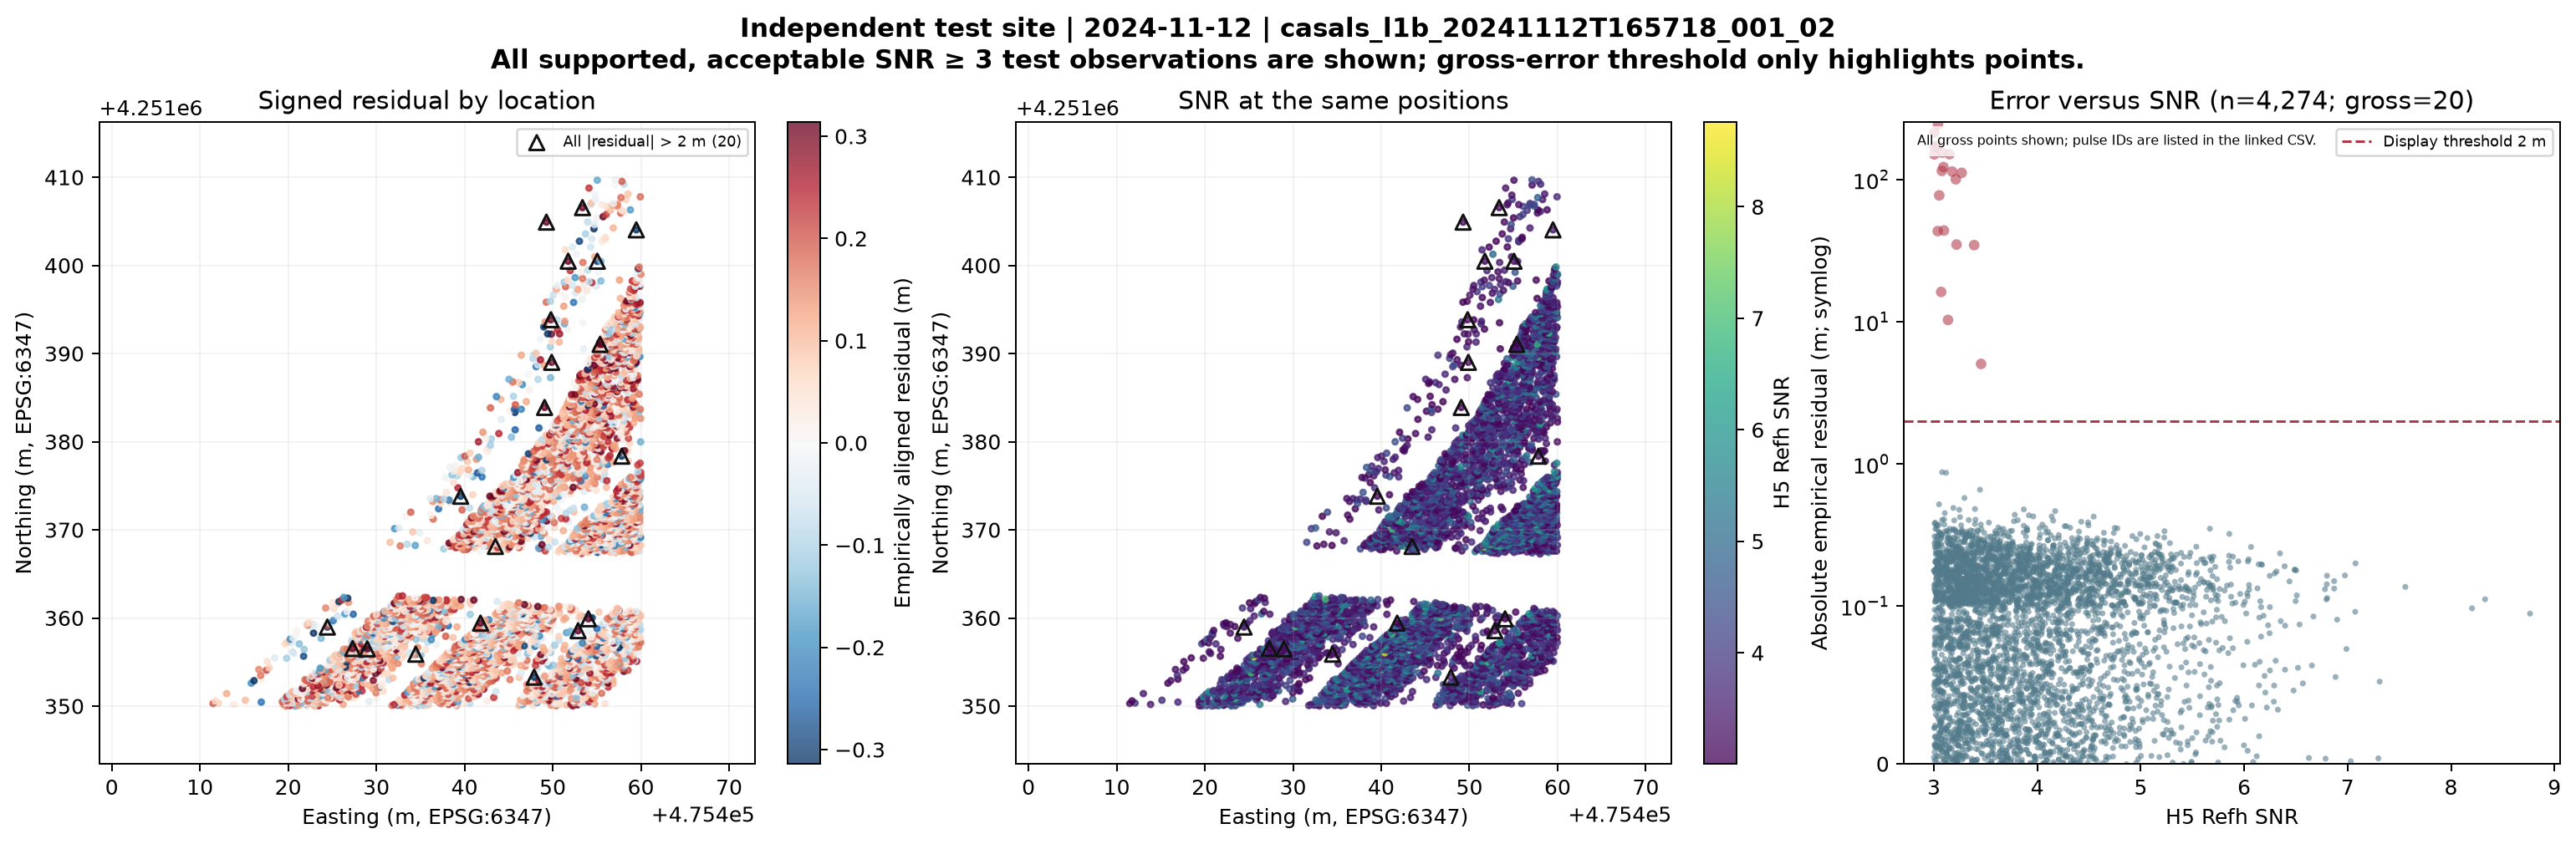

casals_l1b_20241112T165718_001_02: 20 independent-test residuals exceed |2 m|; all are in the saved gross-error table.


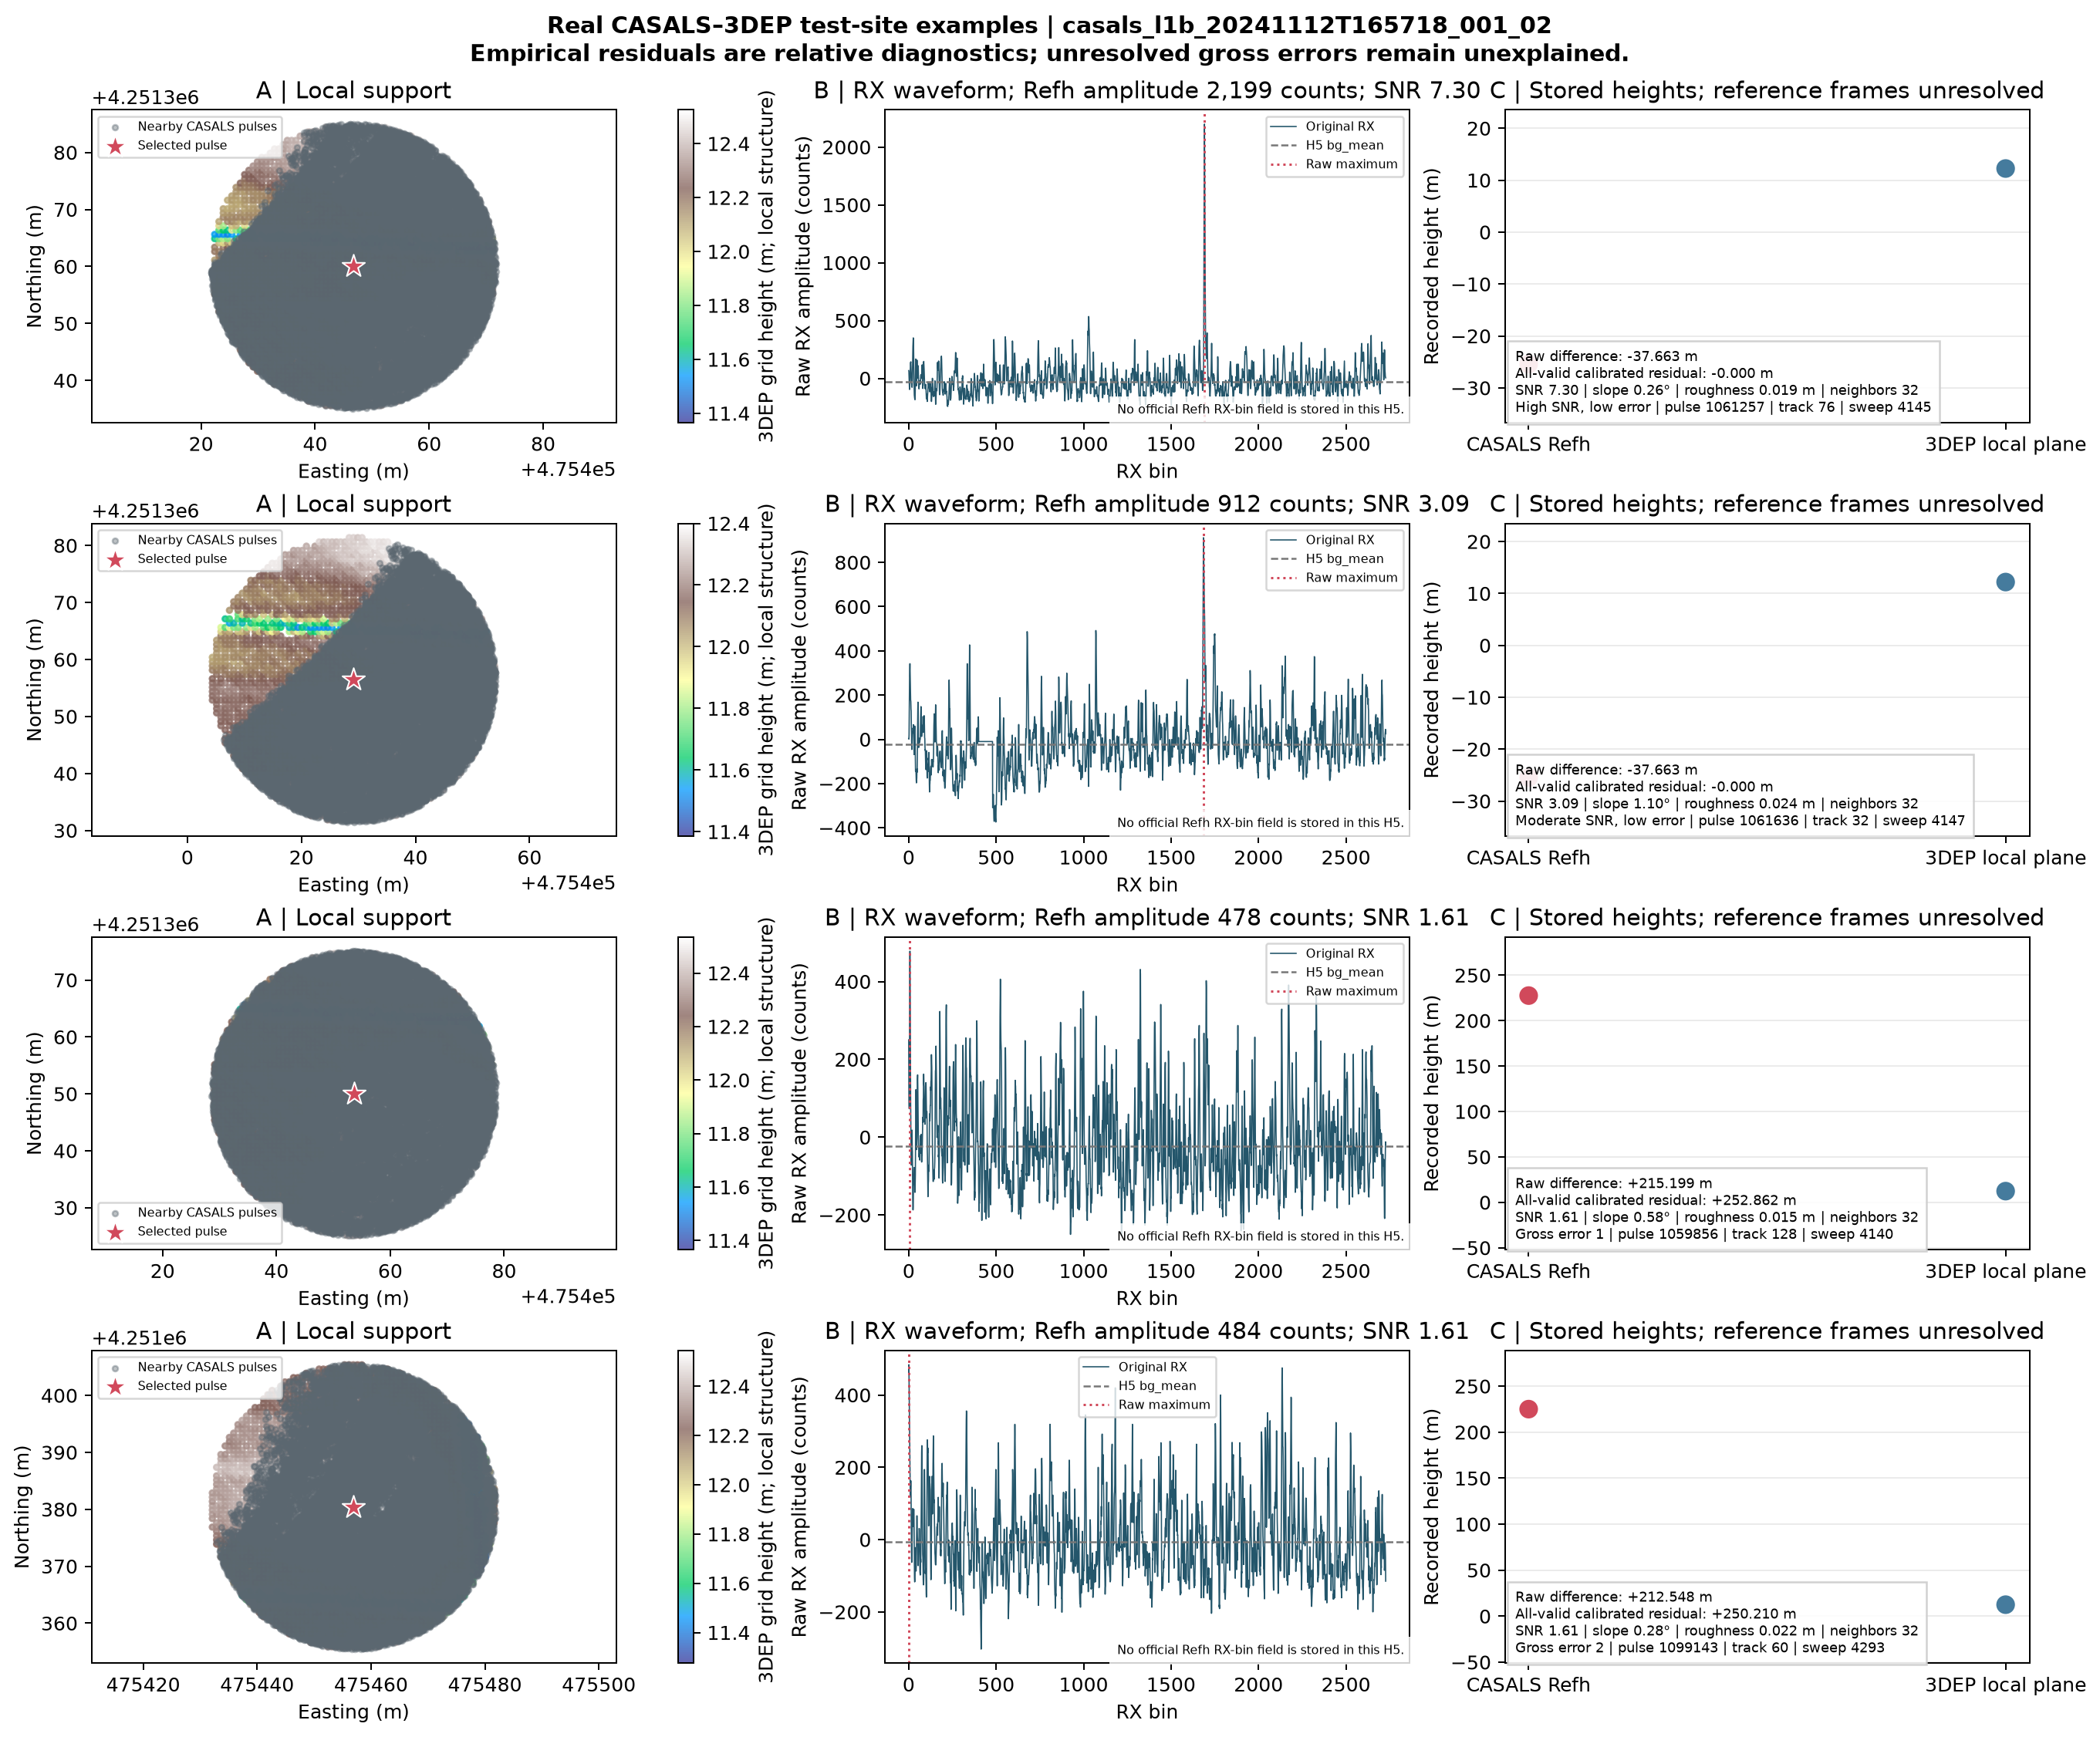

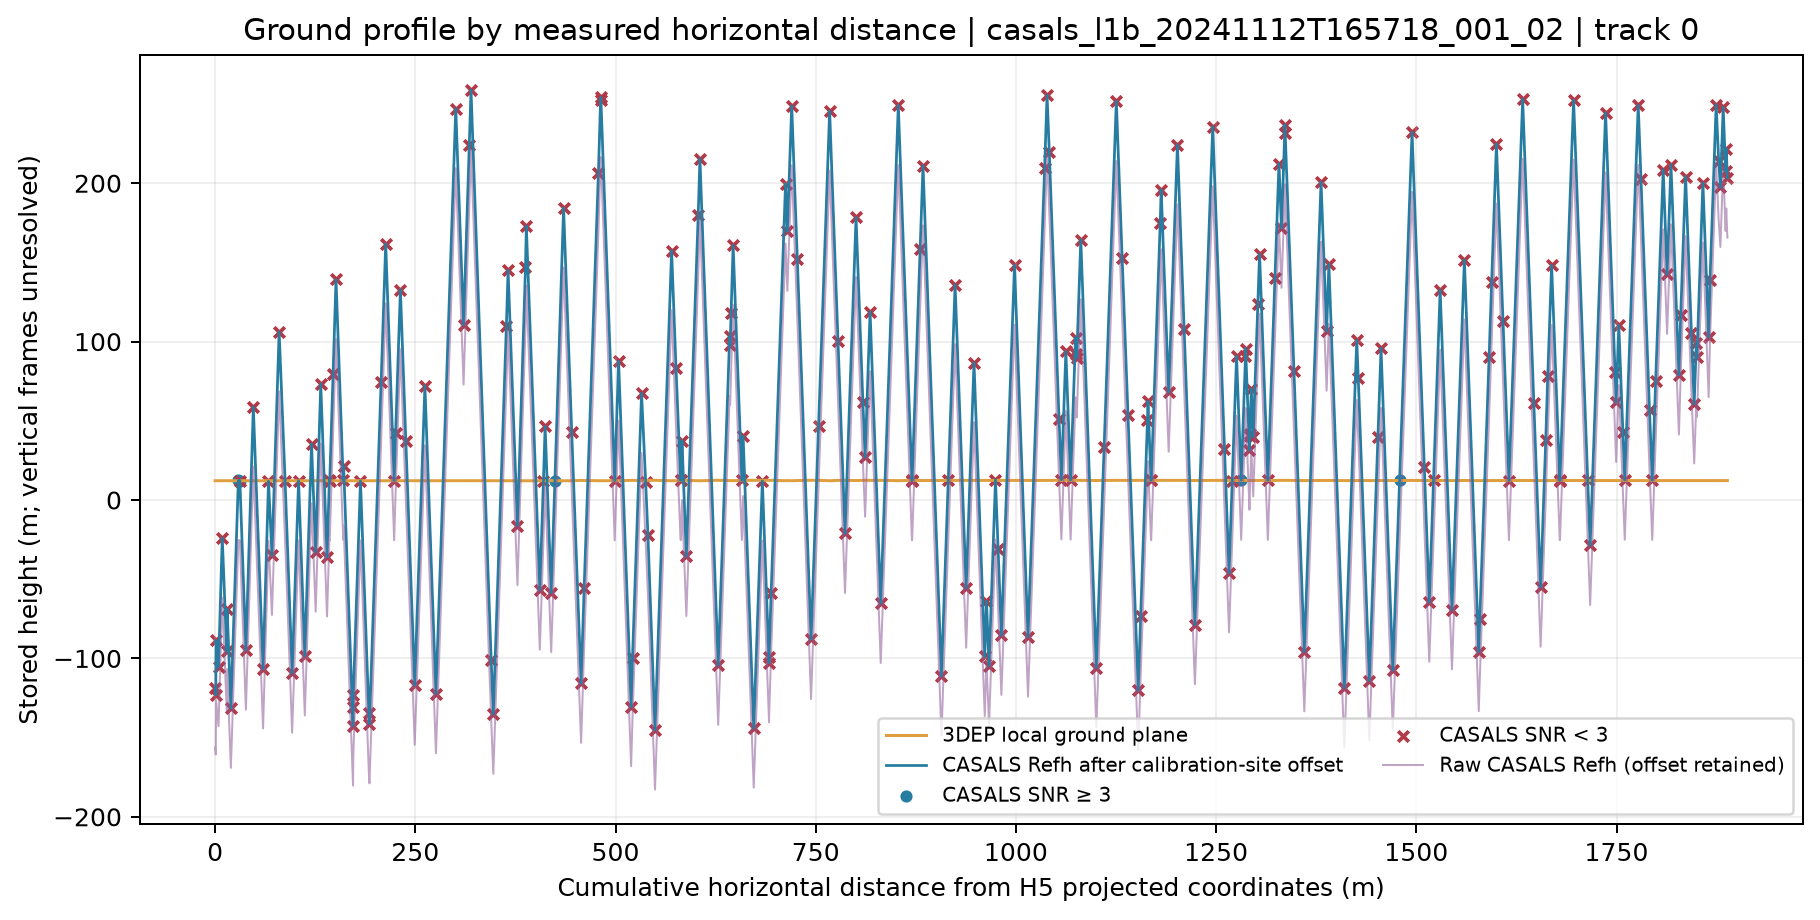

Profile distance spans 1888.5 m using projected H5 XY coordinates.


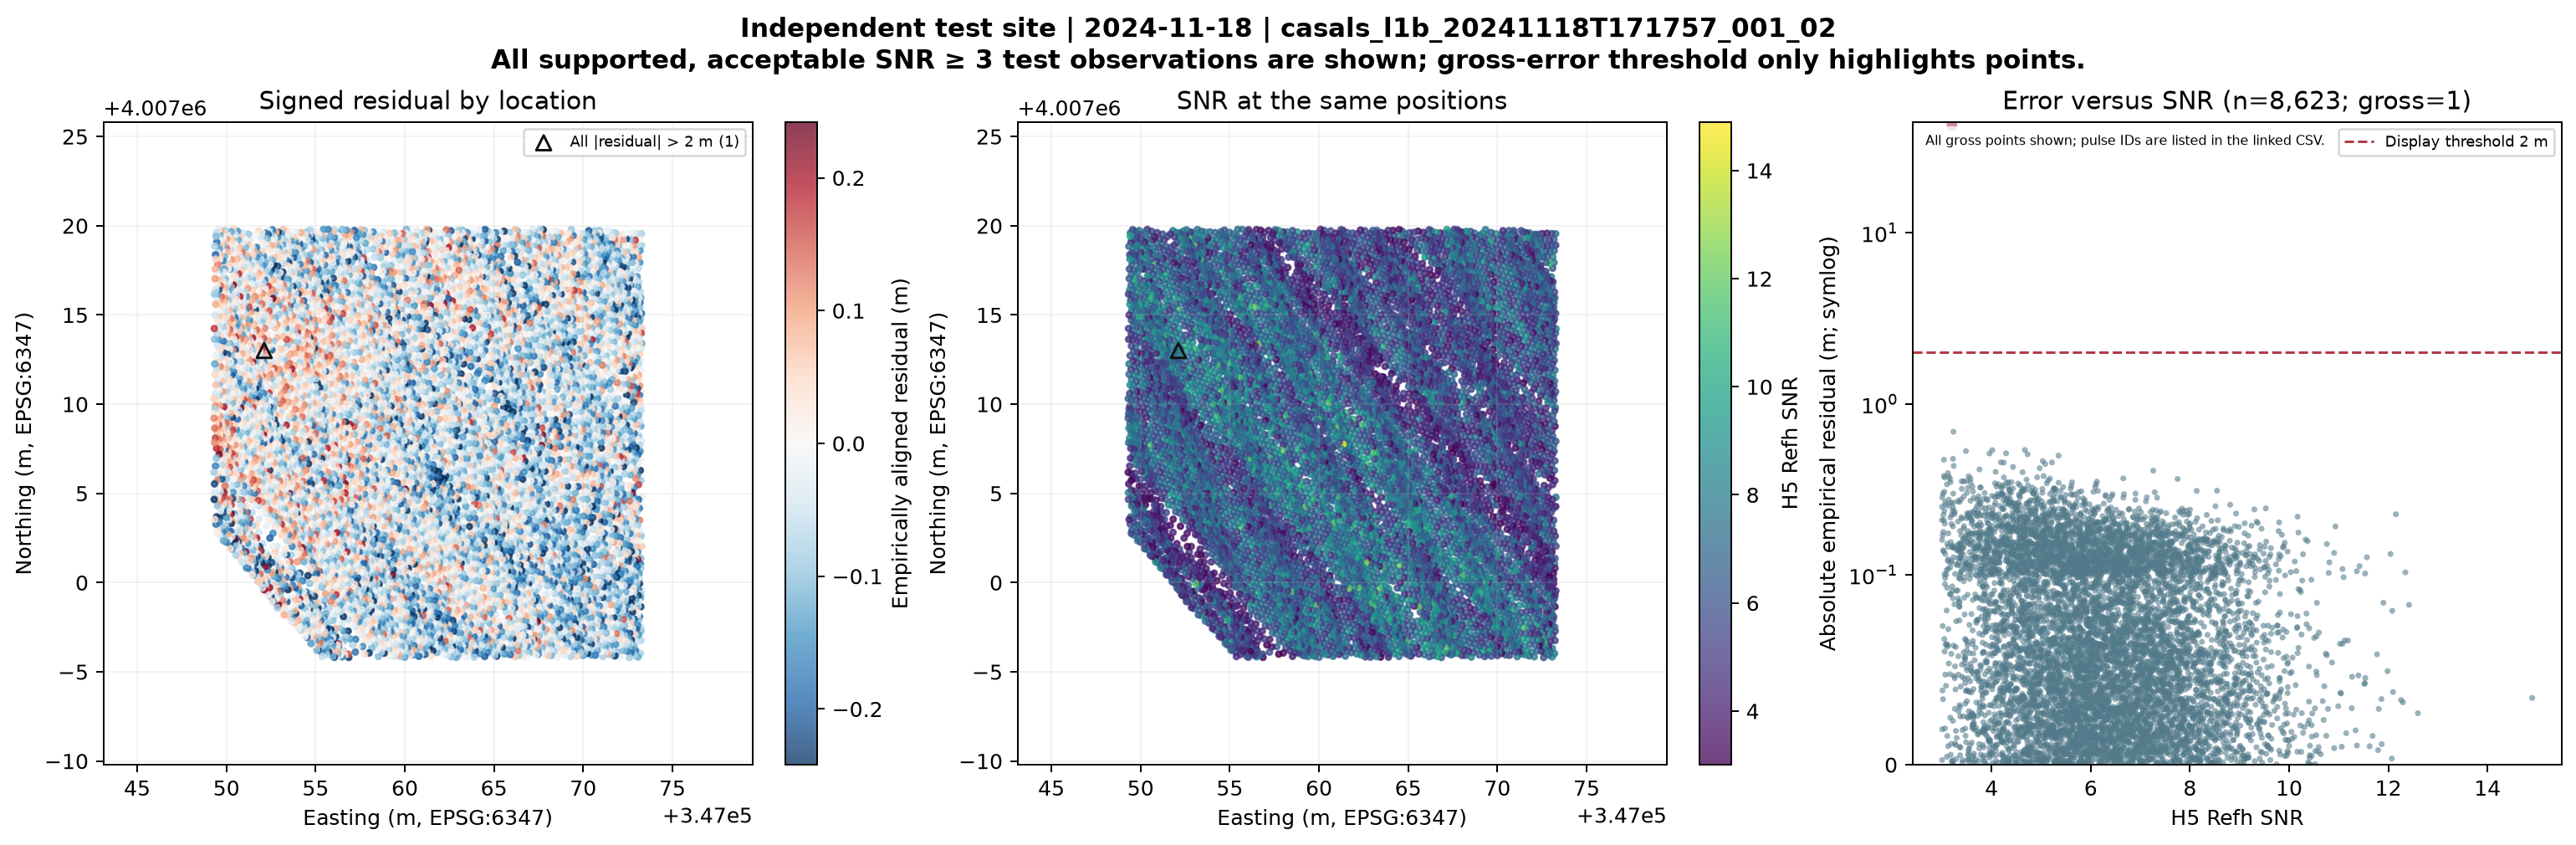

casals_l1b_20241118T171757_001_02: 1 independent-test residuals exceed |2 m|; all are in the saved gross-error table.


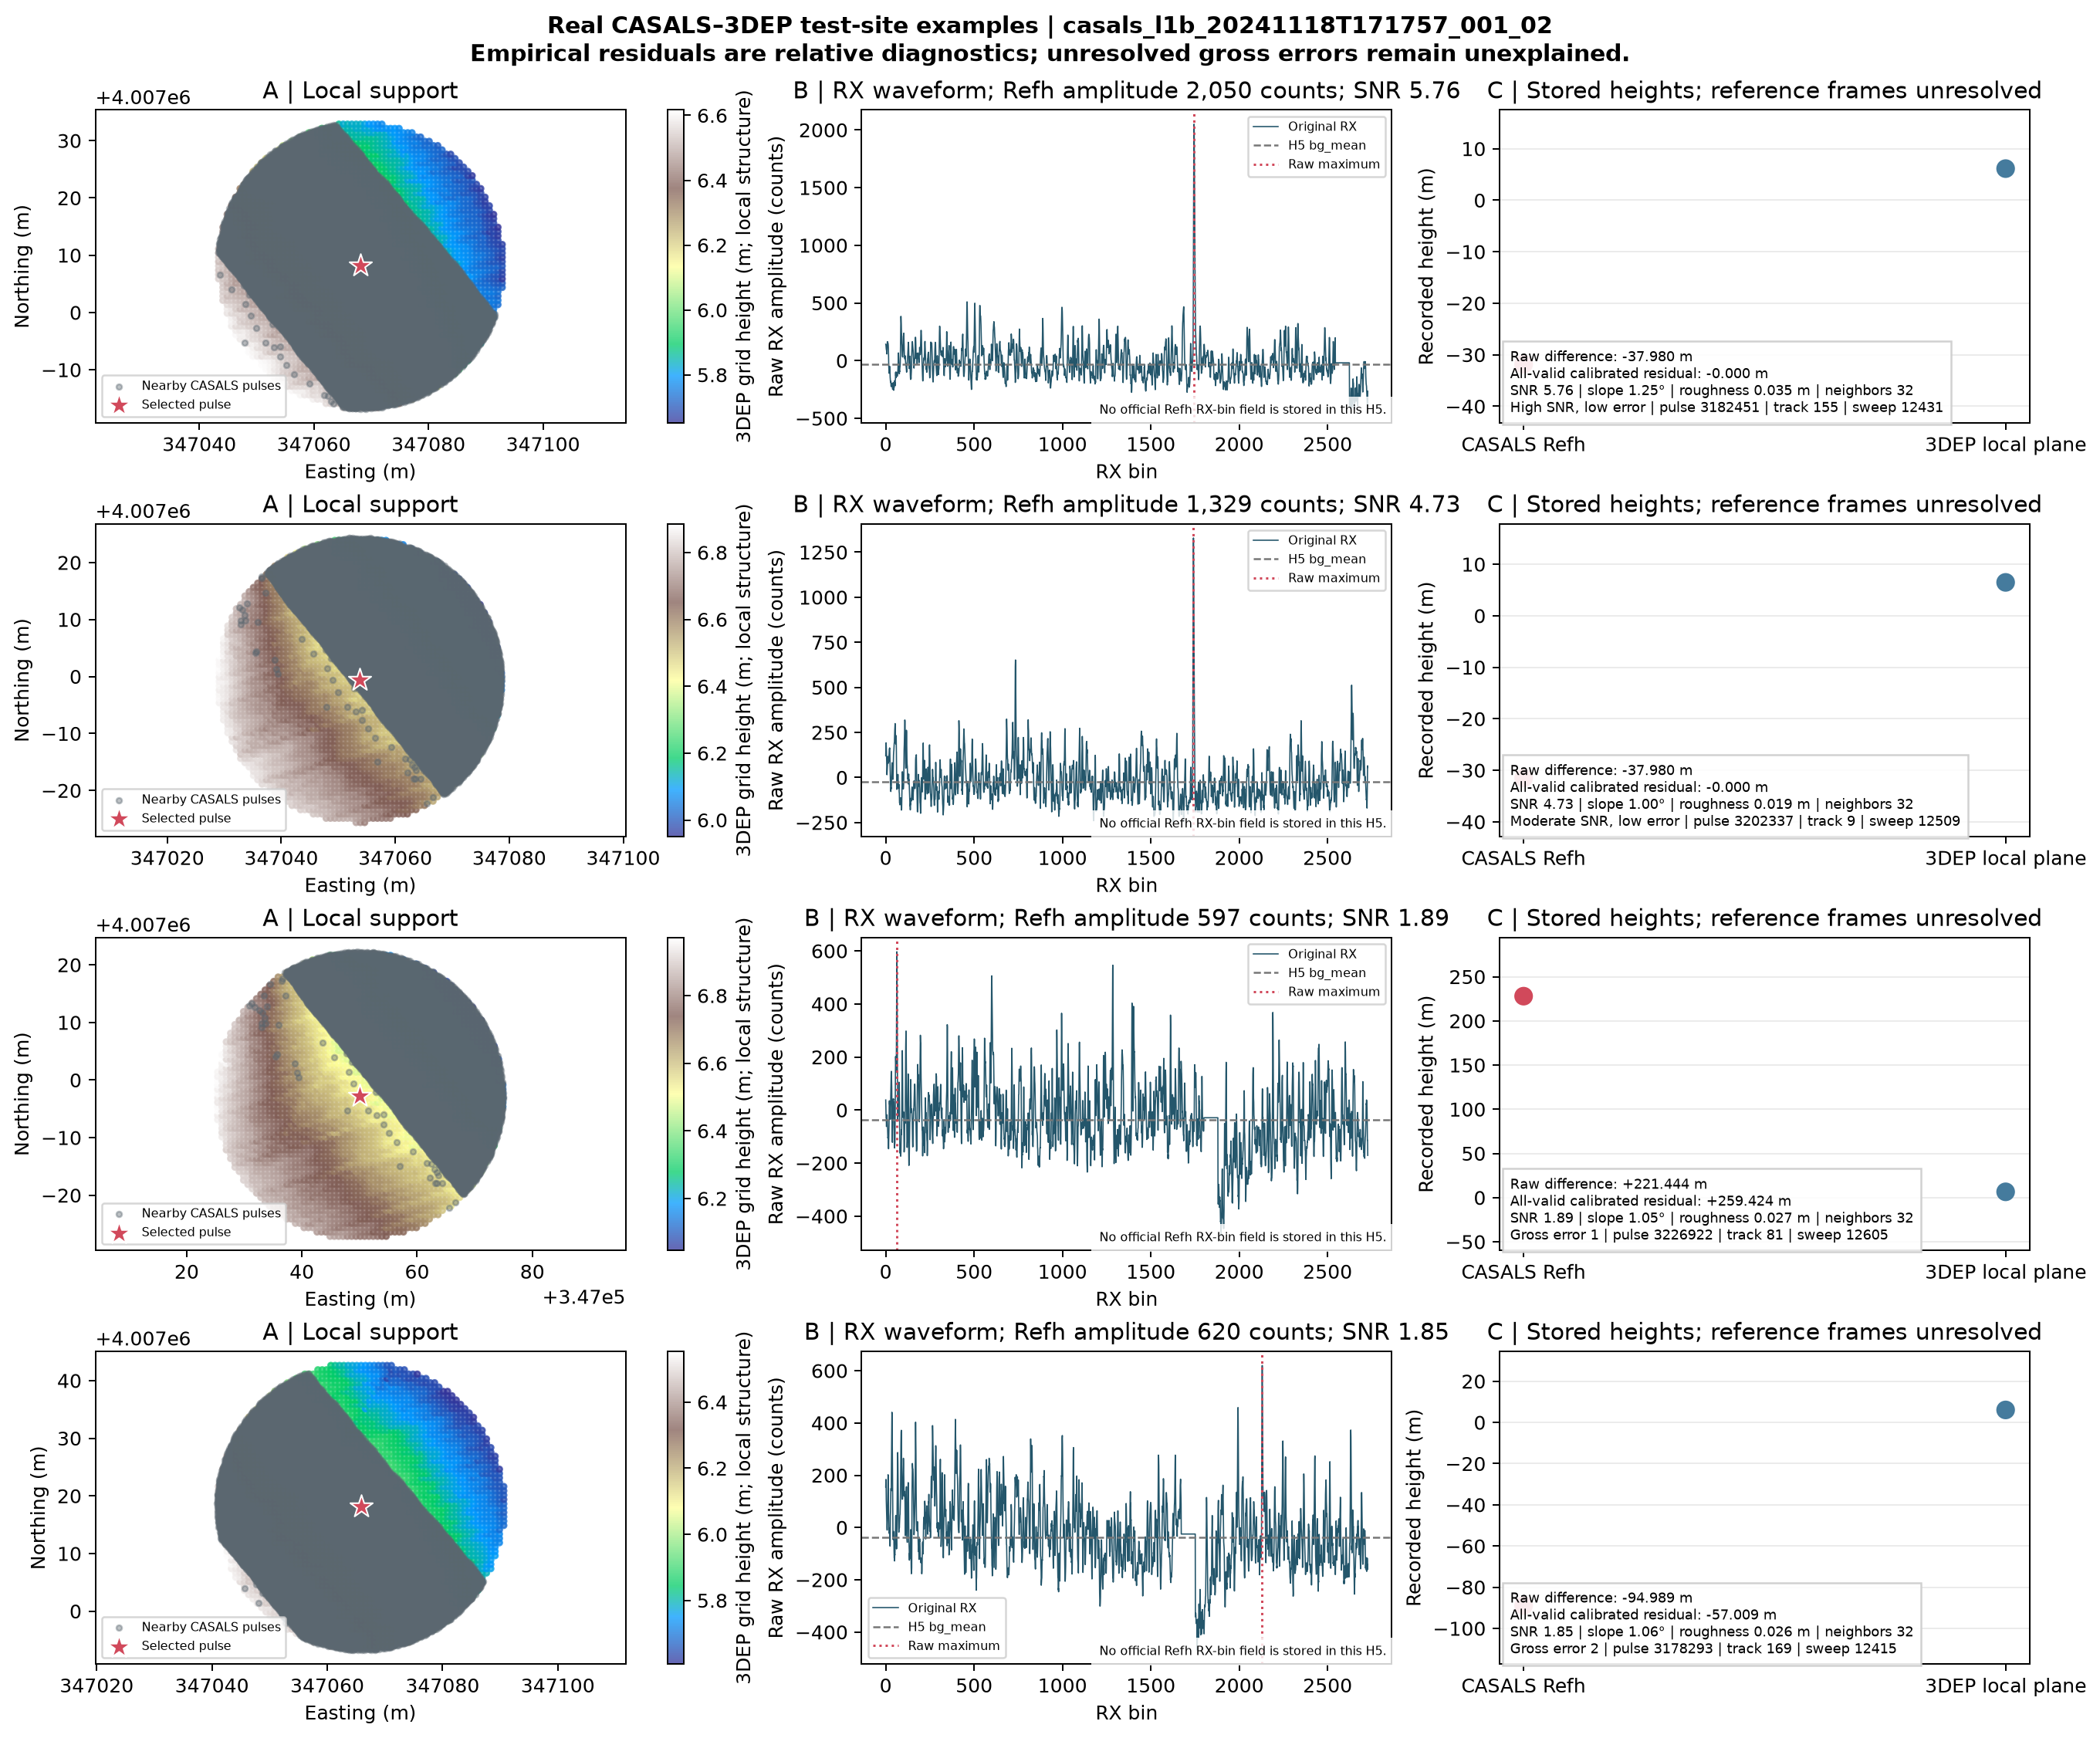

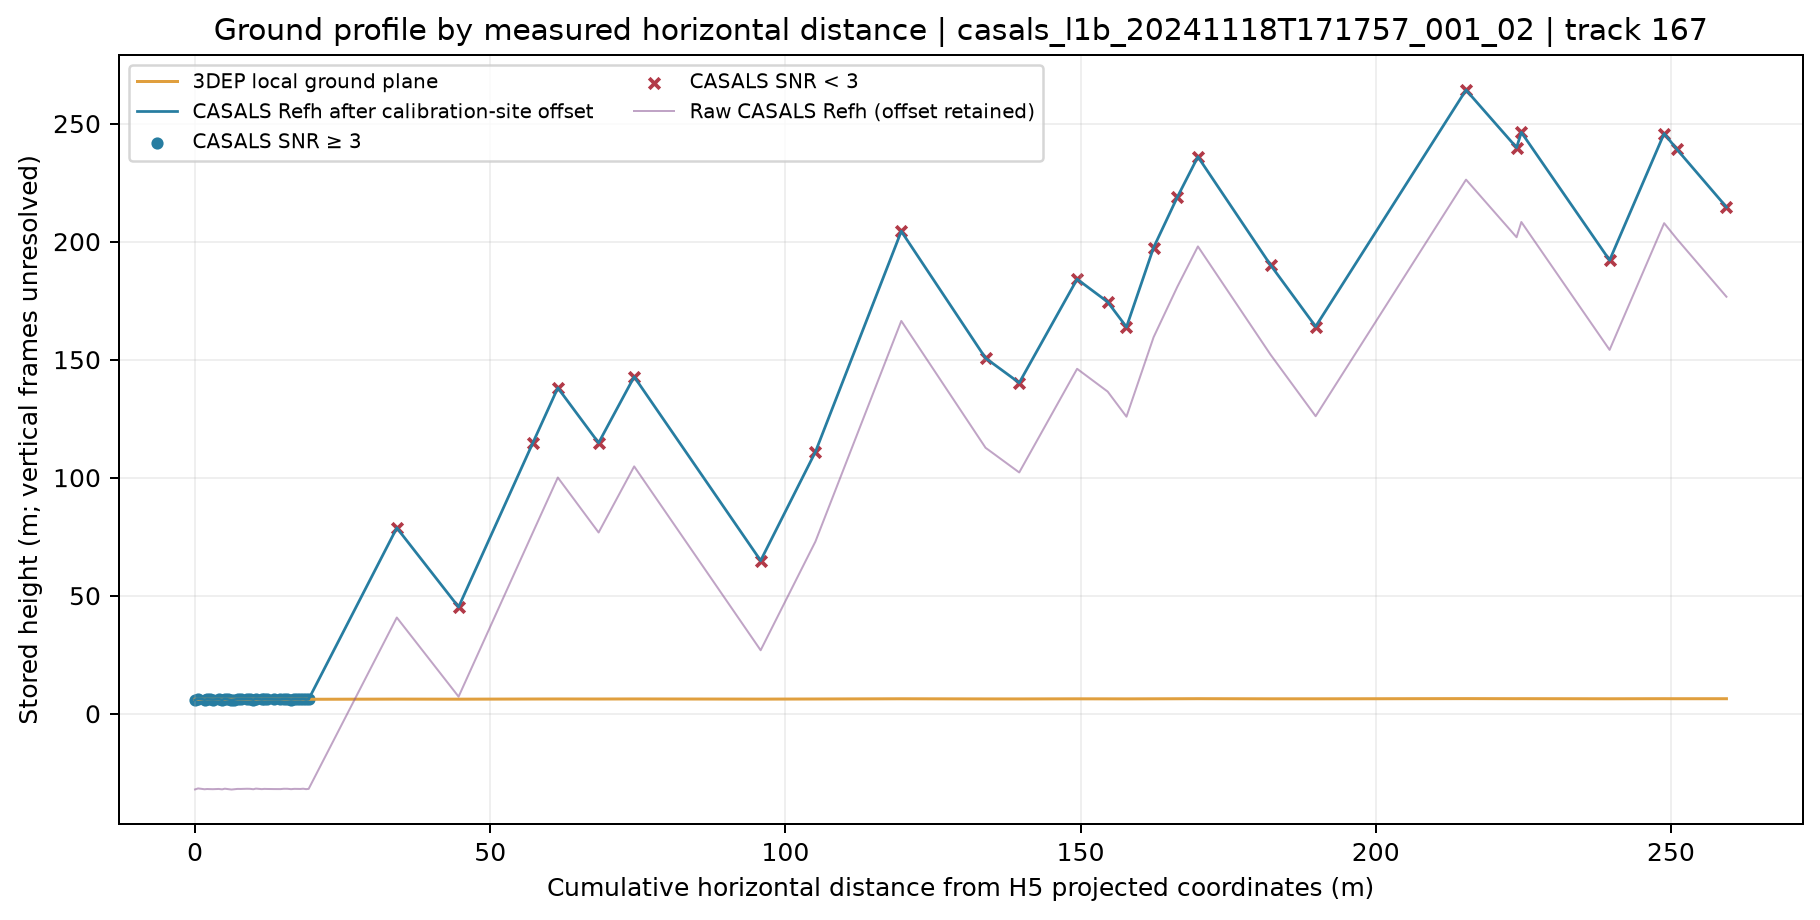

Profile distance spans 259.4 m using projected H5 XY coordinates.


,granule_id,selection_role,selection_status,pulse_index,track_num,sweep_num,refh_snr,raw_difference_plane_m,empirical_holdout_residual_m
0,casals_l1b_20241112T165718_001_02,"High SNR, low error",selected,1061257,76,4145,7.297485,-37.663147,-0.000445
1,casals_l1b_20241112T165718_001_02,"Moderate SNR, low error",selected,1061636,32,4147,3.091083,-37.662787,-0.000084
2,casals_l1b_20241112T165718_001_02,Gross error 1,selected,1059856,128,4140,1.613046,215.199147,252.861850
3,casals_l1b_20241112T165718_001_02,Gross error 2,selected,1099143,60,4293,1.614571,212.547674,250.210377
4,casals_l1b_20241118T171757_001_02,"High SNR, low error",selected,3182451,155,12431,5.762629,-37.980113,-0.000002
5,casals_l1b_20241118T171757_001_02,"Moderate SNR, low error",selected,3202337,9,12509,4.730459,-37.980131,-0.000020
6,casals_l1b_20241118T171757_001_02,Gross error 1,selected,3226922,81,12605,1.889747,221.443912,259.424023
7,casals_l1b_20241118T171757_001_02,Gross error 2,selected,3178293,169,12415,1.853671,-94.988777,-57.008666


In [4]:
for stem, state in PLOT_STATE.items():
    date = "2024-11-12" if "20241112" in stem else "2024-11-18"
    spatial_path = OUT_ROOT / f"10-C_spatial_snr_error_{stem}.png"
    plot_spatial_snr_board(
        granule_id=stem, date=date, test_rows=state["test_rows"],
        residual_m=state["test_residual"], gross_error_threshold_m=GROSS_ERROR_THRESHOLD_M,
        output_path=spatial_path,
    )
    display(Image(filename=str(spatial_path)))
    print(f"{stem}: {state['gross_error_count_snr_ge_3']:,} independent-test residuals exceed |2 m|; "
          "all are in the saved gross-error table.")

    if state["cases"]:
        case_path = OUT_ROOT / f"10-D_real_pulse_cases_{stem}.png"
        plot_elevation_case_board(h5_path=state["h5_path"], cases=state["cases"], output_path=case_path)
        display(Image(filename=str(case_path)))
    else:
        print(f"{stem}: no representative pulse case met the predeclared support rules.")

    profile_path = OUT_ROOT / f"10-E_ground_profile_{stem}_track_{state['profile_track']}.png"
    plot_ground_profile(state["profile"], granule_id=stem,
                        track=state["profile_track"], output_path=profile_path)
    display(Image(filename=str(profile_path)))
    print(f"Profile distance spans {state['profile'].distance_m.iloc[-1]:.1f} m using projected H5 XY coordinates.")

display(CASE_MANIFEST[["granule_id", "selection_role", "selection_status", "pulse_index", "track_num",
                       "sweep_num", "refh_snr", "raw_difference_plane_m",
                       "empirical_holdout_residual_m"]])

## 5. Interpretation and limitations

The central residual widths can remain near 0.1 m while RMSE is much larger because a small number of gross residuals contribute disproportionately to squared error. The full-range panels, exceedance table, and spatial map retain those observations and their locations. The 3DEP interpolation check tests a held-out sample of 3DEP class-2 points against a surface fit; it does not validate CASALS elevations or their vertical datum.

Raw differences preserve the measured offset. Empirical holdout residuals measure agreement after a site-derived median shift. Strict absolute elevation accuracy is unavailable: the H5 Refh vertical meaning and epoch, the LAZ vertical frame, and the historical clipping Z path have not been fully verified. No empirical shift is presented as a datum transformation.